Importing libraries:

In [2]:
import pandas as pd

Load Dataset:

In [4]:
dataset=pd.read_csv("Electricity_Dataset.csv")

View Columns:

In [8]:
dataset.columns

Index(['Month', 'Temperature (°C)', 'Occupants', 'Appliances',
       'Previous_Usage', 'Current_Usage'],
      dtype='object')

Check the Null Values Present in the Dataset: 

In [11]:
dataset.isnull().sum()

Month               0
Temperature (°C)    0
Occupants           0
Appliances          0
Previous_Usage      0
Current_Usage       0
dtype: int64

Input/Output split:

In [14]:
independent=dataset.drop("Current_Usage",axis=1)

In [16]:
dependent=dataset["Current_Usage"]

Convert Nominal to Numerical datas:

In [19]:
independent=pd.get_dummies(independent,drop_first=True,dtype=int)

Train/Split data:

In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(independent,dependent,test_size=0.25,random_state=42)

Feature Scaling:

In [24]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

Train a Model:

In [26]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[-0.78, 2.17,-0.82,...,-0.25,-0.59, 0.07]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,298.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(15)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](15,)","[51.13,42.23,31.53,..., 8.58, 6.02, 4. ]"


Model Evaluation:

In [28]:
y_pred=regressor.predict(X_test)

In [29]:
from sklearn.metrics import r2_score
r_score=r2_score(y_test,y_pred)
print(f"The model performance is {r_score}")

The model performance is 0.9540519360231466


Plot the Graph Actual vs Predicted:

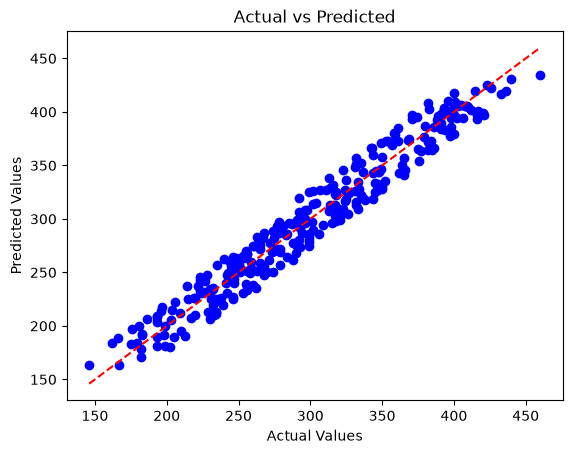

In [36]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')
plt.show()